In [1]:
import os,warnings
import joblib 
import random
import json
import datetime
import tensorflow   as tf
import numpy as np
import keras

from tensorflow.keras.optimizers    import Adam
from tensorflow.keras.callbacks     import EarlyStopping, ReduceLROnPlateau
from tqdm                           import tqdm
from preProcessingData              import PreProcessData
from utility.logger                 import aiLogger
from utility.matpilotDraw           import MatPlot
from tKanModel                          import vaeTKAN
import matplotlib.pyplot            as plt
from keras.models                   import load_model


os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # disabling gpu usage because my cuda is corrupted, needs to be fixed. 

2024-10-03 09:43:11.459099: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-10-03 09:43:11.474227: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-03 09:43:11.492243: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-03 09:43:11.497222: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-03 09:43:11.512285: I tensorflow/core/platform/cpu_feature_guar

In [2]:
with open('model/modelConfig.json', 'r') as configFile:
        config = json.load(configFile)
kanConfig = config["kan"]  

# ---------------------------------    
# Reactor, Separator,Stripper
# ---------------------------------
component  = kanConfig["component"]
modelName  = "kan"


os.environ['CUDA_VISIBLE_DEVICES'] = '1'
# strategy = tf.distribute.MirroredStrategy()


np.random.seed(1)
random.seed(1)
# ---------------------------------
# Pre processing data
# ---------------------------------
preData                         = PreProcessData()
rawData                         = preData.loadCriticalData()                                            # Load the data from critical file
addedVariablesData              = preData.additionEfficiencyVar(rawData)                                # Add some additional efficiency variable
normalizedAllData               = preData.normalizeBuilinFunction(addedVariablesData)                   # Normalize the all data
normalizedHealthy,healthyPos    = preData.getHealthyState(normalizedAllData)       # Load the healthy state
trajectory                      = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= preData.beauEfficiencyCr1 + preData.addEfficiencyCr1)         # Extract the trajectory


listOfData                      = []
for vlTraj in trajectory.values():
        listOfData = listOfData + vlTraj

# clearnData              = preData.cleanData(rawData[preData.crusher1Value])                     # Clean the data by using moving average
# norData                 = preData.normalizeBuilinFunction(clearnData[preData.crusher1Value])    # Normalize the data

# ---------------------------
# All data
# --------------------------
# seqData,_     = preData.splitAllDataIntoSequences(listOfData)
# print(f"The size of the data: {seqData.shape}")

# ---------------------------
# Single sample
# ---------------------------
singleTraject   = trajectory["Lubricación  deficiente"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap'])

trajectory.keys()

Process:43591||2024-10-03 09:43:17,928-INFO [preProcessingData.py:loadCriticalData():220]:Loading critical MOF data from files ...
Process:43591||2024-10-03 09:43:18,379-INFO [preProcessingData.py:loadCriticalData():226]:Finish loading data from files ...


29


Process:43591||2024-10-03 09:43:19,064-INFO [preProcessingData.py:getHealthyState():470]:Getting critical trajectories ...


dict_keys(['Válvula defectuosa', 'Falta de aceite hidráulico', 'Lubricación  deficiente', 'Temperatura fuera de rango', 'Bomba hidráulica con fuga', 'Fuga de aceite', 'Falla sistema de hidroset-poste', 'Mandibulas o revestimiento suelto'])

I0000 00:00:1727941402.845824   43591 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727941402.936805   43591 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727941402.938485   43591 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727941402.942028   43591 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 128, 17)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tkan (TKAN)         │ (None, 128, 40)   │     10,536 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tkan_1 (TKAN)       │ (None, 10)        │     46,244 │ tkan[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         22 │ tkan_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         22 │ tkan_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 56,824 (221.97 KB)

 Trainable params: 56,254 (219.74 KB)

 Non-trainable params: 570 (2.23 KB)

... (5 outputs left out)

 Non-trainable params: 120 (480.00 B)

None
Epoch 1/10
---------------------------------
(None, 128, 17)
---------------------------------
(None, 128, 17)


I0000 00:00:1727941425.829720   43932 service.cc:146] XLA service 0x136e9a00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1727941425.829771   43932 service.cc:154]   StreamExecutor device (0): NVIDIA RTX A2000 8GB Laptop GPU, Compute Capability 8.6
2024-10-03 09:43:46.632746: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-10-03 09:43:49.002468: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8907
I0000 00:00:1727941447.027028   43932 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


89/89 ━━━━━━━━━━━━━━━━━━━━ 78s 400ms/step - kl_loss: 0.0213 - loss: 1.8129 - reconstruction_loss: 0.5972
Epoch 2/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 151ms/step - kl_loss: 2.3302e-06 - loss: 0.1519 - reconstruction_loss: 0.0506
Epoch 3/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 151ms/step - kl_loss: 2.5144e-06 - loss: 0.1500 - reconstruction_loss: 0.0500
Epoch 4/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 154ms/step - kl_loss: 2.8956e-06 - loss: 0.1478 - reconstruction_loss: 0.0493
Epoch 5/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 149ms/step - kl_loss: 2.3499e-06 - loss: 0.1477 - reconstruction_loss: 0.0492
Epoch 6/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 155ms/step - kl_loss: 1.4884e-06 - loss: 0.1451 - reconstruction_loss: 0.0484
Epoch 7/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 156ms/step - kl_loss: 1.1004e-06 - loss: 0.1444 - reconstruction_loss: 0.0481
Epoch 8/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 151ms/step - kl_loss: 7.8069e-07 - loss: 0.1429 - reconstruction_loss: 0.0476
Epoch 9/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 151ms/step - 

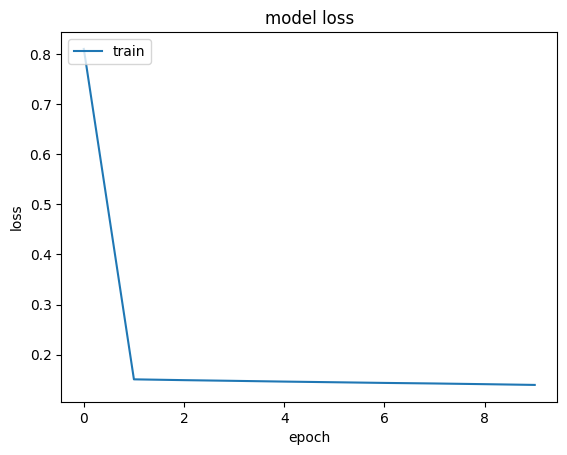

In [3]:
# ---------------------------------
# Model
# ---------------------------------
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
aiModel             = vaeTKAN(config=kanConfig)        

aiModel.compile(optimizer= Adam())
early_stop_loss     = 'loss'
early_stop_callback = EarlyStopping(monitor=early_stop_loss, min_delta = 1e-3, patience=5) 

history = aiModel.fit(
                        x           =   seqData,
                        y           =   seqData,
                        batch_size  =   kanConfig['batchSize'],
                        epochs      =   kanConfig['nEpoch'],
                        shuffle     =   True,
                        callbacks   =   [early_stop_callback],
                        verbose     =   1,
                        )


# ---------------------------------
# Save results
# ---------------------------------
plt.plot(history.history["loss"])
# plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train"],loc ="upper left")

# val_loss = history.history["val_loss"][-1]
# plt.savefig(kanConfig['dir'] + "/" +  "loss" + str(val_loss) + ".png")

(2937, 128, 17)


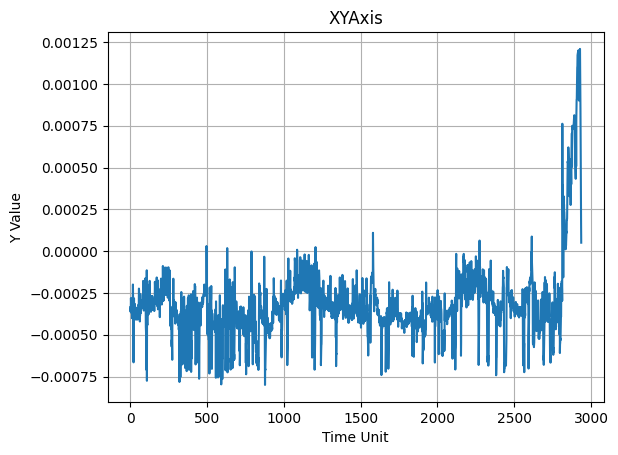

In [4]:
plot = MatPlot()

# ======================================
#  PREPROCESS THE DATA
# --------------------------------------
singleTraject   = trajectory["Falta de aceite hidráulico"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap']) # Split data into each sequence

print(seqData.shape)
zLatent,_     = aiModel(seqData)
# print(zLatent.shape)
hi  = tf.reduce_mean(zLatent, axis=1)

plot.draw1D(hi)